# Notebook 05: Balanced training + ResNet-18 (transfer learning)

This notebook answers the advisor's feedback (27 Oct 2026):
1. **Balance the classes** to reduce bias towards `No-Anomaly` (50 % of the data).
2. **Choose the model from published work** on the same dataset.

### What the literature on this dataset (Raptor Maps InfraredSolarModules) did
| Paper | Model | Imbalance handling | Reported result |
|---|---|---|---|
| Fonseca Alves et al. 2021, *Renewable Energy* | CNN | none | fault / no-fault 92.5 %, 11 classes 66.4 % |
| Le et al. 2021, *Sustainable Energy Tech. & Assessments* | ResNet + ensemble | – | fault / no-fault ≈ 94 %, 12 classes ≈ 86 % |
| Korkmaz & Açıkgöz 2022, *Eng. Appl. of AI* | Transfer learning + multi-scale CNN | oversampling with augmentation | fault / no-fault 97.3 %, 11 classes 93.5 % |

Our Notebook 02 CNN (accuracy 0.79, macro-F1 0.66, no balancing) is close to Fonseca Alves et al.
So the two things the better papers add are exactly the advisor's two points: **balanced training** and a **pretrained ResNet** (transfer learning).

### The 4 runs in this notebook (change one thing at a time)
| Run | Model | Classes | Balancing | Compare with |
|---|---|---|---|---|
| R05 | SmallCNN (same as Notebook 02) | 12 | balanced sampler | R04 → effect of balancing only |
| R06 | ResNet-18, ImageNet-pretrained | 12 | balanced sampler | R05 → effect of the model |
| R07 | SmallCNN | 5 groups | balanced sampler | R05 → effect of merging classes |
| R08 | ResNet-18, ImageNet-pretrained | 5 groups | balanced sampler | R07 |

Every run uses the **same `splits.csv`**, so all results are measured on the same 3,000 test images.
Each run is recorded automatically: a summary row and every setting in `experiment_log.xlsx` (sheets *Runs* and *Parameters*), plus its own folder `runs/<RunID>_<date-time>/` with the full configuration, the training log of every epoch, per-class test results, the confusion matrix and every test prediction (details in section 6).

### Before you run
* The ResNet-18 pretrained weights (≈ 45 MB) are downloaded from the internet the first time.
* Expected time on an RTX 4070 Ti: about 1–3 minutes per SmallCNN run and 3–8 minutes per ResNet-18 run.

## 0. Imports, device and data folder
The data folder is searched in three places: `../archive/` (PC: `D:\Senior Project\archive`, next to the notebook folder),
`../data/archive/`, and `archive/` (Mac: inside the project folder).

In [1]:
import time, datetime, platform
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from torchvision.models import (resnet18, ResNet18_Weights, resnet50, ResNet50_Weights,
                                efficientnet_b0, EfficientNet_B0_Weights)

from sklearn.metrics import f1_score, accuracy_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
REL = Path("2020-02-14_InfraredSolarModules/InfraredSolarModules")
CANDIDATES = [Path("../archive"), Path("../data/archive"), Path("archive"), Path("../../archive")]
DATA_DIR = next((r / REL for r in CANDIDATES if (r / REL / "images").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(f"Data folder not found. This notebook runs in {Path.cwd()}\nLooked in:\n  "
                            + "\n  ".join(str((r / REL).resolve()) for r in CANDIDATES))

if torch.cuda.is_available():
    device = torch.device("cuda")
    HARDWARE = torch.cuda.get_device_name(0)
    torch.backends.cudnn.benchmark = True          # lets cuDNN pick the fastest convolution algorithm
elif torch.backends.mps.is_available():
    device = torch.device("mps"); HARDWARE = "Apple GPU (mps)"
else:
    device = torch.device("cpu"); HARDWARE = platform.processor() or "CPU"

Path("figures").mkdir(exist_ok=True)
Path("checkpoints").mkdir(exist_ok=True)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("device:", device, "|", HARDWARE)
print("data:", DATA_DIR.resolve())

PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126
device: cuda | NVIDIA GeForce RTX 4070 Ti
data: D:\Senior Project\archive\2020-02-14_InfraredSolarModules\InfraredSolarModules


## 1. Load the split and define the 5 merged groups
The 12 original classes are merged by **how much power they cost and what the maintenance action is**:

| Group | Original classes | Typical power effect |
|---|---|---|
| Cell-level | Cell, Cell-Multi, Cracking, Hot-Spot, Hot-Spot-Multi | small (a few %) |
| Substring-level | Diode, Diode-Multi | ≈ 33 % per shorted bypass diode (confirmed on DTU) |
| Module-level | Offline-Module | 100 % |
| External | Shadowing, Vegetation, Soiling | depends; fixed by cleaning / trimming, not by repair |
| No-Anomaly | No-Anomaly | 0 % |

In [2]:
split = pd.read_csv("splits.csv")

GROUP = {
    "Cell": "Cell-level", "Cell-Multi": "Cell-level", "Cracking": "Cell-level",
    "Hot-Spot": "Cell-level", "Hot-Spot-Multi": "Cell-level",
    "Diode": "Substring-level", "Diode-Multi": "Substring-level",
    "Offline-Module": "Module-level",
    "Shadowing": "External", "Vegetation": "External", "Soiling": "External",
    "No-Anomaly": "No-Anomaly",
}
missing = set(split.label) - set(GROUP)
assert not missing, f"classes without a group: {missing}"
split["group"] = split.label.map(GROUP)

CLASS_SETS = {
    "12": sorted(split.label.unique()),
    "5": ["Cell-level", "Substring-level", "Module-level", "External", "No-Anomaly"],
}
print(split.groupby(["split"]).size().to_string())
print("\nTraining images per group:")
print(split[split.split == "train"].group.value_counts().to_string())

split
test      3000
train    14000
val       3000

Training images per group:
group
No-Anomaly         7000
Cell-level         3220
External           2029
Substring-level    1172
Module-level        579


## 2. Load all images once (same preprocessing as Notebook 02)
Per-image normalisation `z = (I − median) / std`: each pixel says how much hotter it is than the rest of the same module.
All 20,000 images are only 40 × 24 pixels, so they fit in memory easily (≈ 77 MB).

In [3]:
t0 = time.time()
imgs = np.stack([np.asarray(Image.open(DATA_DIR / p), dtype=np.float32) / 255.0 for p in split.path])
med = np.median(imgs, axis=(1, 2), keepdims=True)
std = imgs.std(axis=(1, 2), keepdims=True) + 1e-6
Z = torch.from_numpy((imgs - med) / std).unsqueeze(1)     # (20000, 1, 40, 24)
print("images:", tuple(Z.shape), f"loaded in {time.time() - t0:.1f}s")

images: (20000, 1, 40, 24) loaded in 3.3s


## 3. Dataset with augmentation
Training images only: random horizontal / vertical flip (as before) **plus a small random shift of up to 2 pixels**.
The shift is new: with balanced sampling, rare-class images are shown many times per epoch,
so we make each repeat slightly different (this is the "oversampling with augmentation" used by Korkmaz & Açıkgöz 2022).
Validation and test images are **never** augmented or resampled: they keep the real class proportions.

In [4]:
class IRModules(Dataset):
    def __init__(self, idx, y, augment=False, max_shift=2):
        self.idx = torch.as_tensor(idx)
        self.y = torch.as_tensor(y).long()
        self.augment, self.s = augment, max_shift
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = Z[self.idx[i]]                                   # (1, 40, 24)
        if self.augment:
            if torch.rand(1) < 0.5: x = torch.flip(x, dims=[2])
            if torch.rand(1) < 0.5: x = torch.flip(x, dims=[1])
            s = self.s
            if s > 0:                                        # random shift: pad by s pixels, then crop back to 40 × 24
                x = F.pad(x.unsqueeze(0), (s, s, s, s), mode="replicate").squeeze(0)
                dy, dx = torch.randint(0, 2 * s + 1, (2,)).tolist()
                x = x[:, dy:dy + 40, dx:dx + 24]
        return x, self.y[i]

## 4. Balanced sampling: how the classes are balanced
`WeightedRandomSampler` picks training images with probability ∝ 1 / (size of its class).
Every class is then drawn about equally often, so each batch is roughly balanced:
* rare classes (e.g. Diode-Multi, 105 training images) are **oversampled** (seen many times, each time augmented differently),
* `No-Anomaly` (7,000 training images) is **undersampled** (only part of it is seen per epoch, a different part each epoch).

One epoch still has 14,000 draws, so the training time stays the same as Notebook 02.
Because the batches are already balanced, the loss **no longer uses class weights** (using both would correct the imbalance twice).

In [5]:
def make_loaders(class_set, balance="sampler", batch=128, seed=SEED):
    classes = CLASS_SETS[class_set]
    col = "label" if class_set == "12" else "group"
    c2i = {c: i for i, c in enumerate(classes)}
    y_all = split[col].map(c2i).values
    parts = {s: np.where(split.split.values == s)[0] for s in ("train", "val", "test")}

    tr = parts["train"]
    counts = np.bincount(y_all[tr], minlength=len(classes))
    g = torch.Generator().manual_seed(seed)
    if balance in ("sampler", "sqrt"):                       # "sqrt" = softer balancing: p ∝ 1/sqrt(n_class)
        w_sample = counts[y_all[tr]] ** (-1.0 if balance == "sampler" else -0.5)
        sampler = WeightedRandomSampler(torch.as_tensor(w_sample, dtype=torch.double),
                                        num_samples=len(tr), replacement=True, generator=g)
        train_dl = DataLoader(IRModules(tr, y_all[tr], augment=True), batch_size=batch, sampler=sampler)
        class_w = None
    else:                                                    # "weights": Notebook 02 style, sqrt class weights, no resampling
        train_dl = DataLoader(IRModules(tr, y_all[tr], augment=True), batch_size=batch, shuffle=True, generator=g)
        class_w = torch.tensor((len(tr) / (len(classes) * counts)) ** 0.5, dtype=torch.float32)
    val_dl = DataLoader(IRModules(parts["val"], y_all[parts["val"]]), batch_size=512)
    test_dl = DataLoader(IRModules(parts["test"], y_all[parts["test"]]), batch_size=512)
    return classes, train_dl, val_dl, test_dl, counts, class_w

# quick check: class counts in 20 balanced batches
classes, tdl, *_ = make_loaders("12")
seen = np.zeros(len(classes), int)
for k, (_, yb) in enumerate(tdl):
    seen += np.bincount(yb.numpy(), minlength=len(classes))
    if k == 19: break
print(pd.DataFrame({"class": classes, "drawn in 20 batches": seen}).to_string(index=False))

         class  drawn in 20 batches
          Cell                  209
    Cell-Multi                  197
      Cracking                  226
         Diode                  202
   Diode-Multi                  229
      Hot-Spot                  225
Hot-Spot-Multi                  200
    No-Anomaly                  212
Offline-Module                  208
     Shadowing                  239
       Soiling                  217
    Vegetation                  196


## 5. The two models
**SmallCNN**: exactly the model of Notebook 02 (782,188 parameters), so R05 vs R04 shows the effect of balancing alone.

**ResNet-18 (transfer learning)**: an 18-layer network with *residual (shortcut) connections*, pretrained on ImageNet (1.2 million everyday photos).
Its early layers already detect edges, blobs and textures, which also appear in thermal images. We only replace the last layer (1000 ImageNet classes → our 12 or 5) and fine-tune the whole network.

Two adaptations, both done inside `forward()` on the GPU:
* **Resize** 40 × 24 → 160 × 96 (× 4). ResNet shrinks the image 32 ×, so 160 × 96 ends as a 5 × 3 map, the same as SmallCNN's last map. 40 × 24 directly would shrink to almost nothing.
* **Gray → 3 channels**: the pretrained first layer expects RGB, so the single channel is repeated 3 times.

In [6]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.MaxPool2d(2))

class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 32), conv_block(32, 64), conv_block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(128 * 5 * 3, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

class ResNet18TL(nn.Module):
    def __init__(self, n_classes, size=(160, 96), pretrained=True):
        super().__init__()
        self.size = size
        self.net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        self.net.fc = nn.Linear(self.net.fc.in_features, n_classes)   # new last layer
    def forward(self, x):
        x = F.interpolate(x, size=self.size, mode="bilinear", align_corners=False)
        return self.net(x.repeat(1, 3, 1, 1))

class PretrainedTL(nn.Module):
    # Same idea as ResNet18TL for other ImageNet-pretrained backbones (used in section 16)
    def __init__(self, arch, n_classes, size=(160, 96)):
        super().__init__()
        self.size = size
        if arch == "resnet50":
            self.net = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
            self.net.fc = nn.Linear(self.net.fc.in_features, n_classes)
        elif arch == "efficientnet_b0":
            self.net = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
            self.net.classifier[1] = nn.Linear(self.net.classifier[1].in_features, n_classes)
        else:
            raise ValueError(arch)
    def forward(self, x):
        x = F.interpolate(x, size=self.size, mode="bilinear", align_corners=False)
        return self.net(x.repeat(1, 3, 1, 1))

def build_model(name, n_classes):
    return {"SmallCNN": lambda: SmallCNN(n_classes),
            "ResNet18TL": lambda: ResNet18TL(n_classes),
            "ResNet50TL": lambda: PretrainedTL("resnet50", n_classes),
            "EffNetB0TL": lambda: PretrainedTL("efficientnet_b0", n_classes)}[name]()

MODEL_INFO = {
    "SmallCNN": "SmallCNN, 3 × [Conv-BN-ReLU ×2 → MaxPool], 32/64/128, Dropout 0.3, FC 256",
    "ResNet18TL": "ResNet-18, ImageNet-pretrained (IMAGENET1K_V1), all layers fine-tuned, new FC; input resized 40×24 → 160×96 bilinear, gray repeated to 3 channels",
    "ResNet50TL": "ResNet-50, ImageNet-pretrained (IMAGENET1K_V2), all layers fine-tuned, new FC; input resized 40×24 → 160×96 bilinear, gray repeated to 3 channels",
    "EffNetB0TL": "EfficientNet-B0, ImageNet-pretrained (IMAGENET1K_V1), all layers fine-tuned, new classifier; input resized 40×24 → 160×96 bilinear, gray repeated to 3 channels",
}

for name, m in [("SmallCNN", SmallCNN(12)), ("ResNet18TL", ResNet18TL(12))]:
    n_par = sum(p.numel() for p in m.parameters() if p.requires_grad)
    with torch.no_grad():
        out = m.eval()(torch.zeros(2, 1, 40, 24))
    print(f"{name:11s} parameters = {n_par:,}   output = {tuple(out.shape)}")

SmallCNN    parameters = 782,188   output = (2, 12)
ResNet18TL  parameters = 11,182,668   output = (2, 12)


## 6. One function that trains, tests and logs a run
Same training loop as Notebook 02 (forward → loss → backward → step; keep the epoch with the best **validation** macro-F1).
After training, the best checkpoint is evaluated **once** on the test set:
* accuracy, macro-F1, and precision / recall / F1 of every class,
* fault vs no-fault accuracy,
* for 12-class runs, also the score after mapping predictions to the 5 groups, so 12-class and 5-group models can be compared on the same task.

### What is recorded for every run
Each run gets its own folder `runs/<RunID>_<date-time>/` (a re-run never overwrites an older folder):

| File | Content |
|---|---|
| `config.json` | every setting of the run (model, optimizer, learning rate, epochs, batch size, balancing, augmentation, seed, classes, images per class), the environment (Python, PyTorch, CUDA, cuDNN, GPU, operating system), the fingerprint (MD5) of `splits.csv`, and all final results |
| `train.log` | everything printed during the run, with times |
| `history.csv` | one row per epoch: learning rate, training loss, training accuracy, validation loss / accuracy / macro-F1, seconds |
| `test_per_class.csv` | precision, recall, F1 and number of test images of every class |
| `confusion_matrix.csv` | the test confusion matrix as counts (rows = true class, columns = predicted class) |
| `test_predictions.csv` | for every test image: file, true class, predicted class |
| `curves_and_cm.png` | learning curves + confusion matrix |

The best weights are saved in `checkpoints/`, and a summary row plus all settings are appended to `experiment_log.xlsx`.
The MD5 fingerprint proves later that every run used exactly the same data split.

In [7]:
import json, sys, hashlib
from sklearn.metrics import precision_recall_fscore_support

SPLIT_MD5 = hashlib.md5(Path("splits.csv").read_bytes()).hexdigest()

def environment():
    return {
        "python": sys.version.split()[0], "pytorch": torch.__version__, "torchvision": torchvision.__version__,
        "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
        "device": str(device), "hardware": HARDWARE, "os": platform.platform(),
        "data_dir": str(DATA_DIR.resolve()), "splits_md5": SPLIT_MD5,
    }

def logged_ids():
    ids = set()
    if Path("results_05.csv").exists():
        ids |= set(pd.read_csv("results_05.csv").run_id.astype(str))
    if Path("experiment_log.xlsx").exists():
        from openpyxl import load_workbook
        ws = load_workbook("experiment_log.xlsx", read_only=True)["Runs"]
        ids |= {str(r[0]) for r in ws.iter_rows(min_row=2, values_only=True) if r and r[0]}
    return ids

def next_free_id(run_id):
    # R05 already logged -> R05-rerun1, then R05-rerun2, ...
    ids = logged_ids()
    if run_id not in ids:
        return run_id
    k = 1
    while f"{run_id}-rerun{k}" in ids:
        k += 1
    return f"{run_id}-rerun{k}"

def predict(model, dl, criterion=None):
    model.eval()
    ys, ps, loss_sum = [], [], 0.0
    with torch.no_grad():
        for x, y in dl:
            out = model(x.to(device))
            if criterion is not None:
                loss_sum += criterion(out, y.to(device)).item() * len(y)
            ps.append(out.argmax(1).cpu()); ys.append(y)
    yt, pt = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return (yt, pt, loss_sum / len(yt)) if criterion is not None else (yt, pt)

def run_experiment(run_id, model_name, class_set, balance="sampler", epochs=40, lr=1e-3,
                   weight_decay=1e-4, batch=128, max_shift=2, note="", seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    rerun_of = None
    free_id = next_free_id(run_id)                          # never overwrite a logged run
    if free_id != run_id:
        rerun_of, run_id = run_id, free_id
        note = f"Re-run of {rerun_of} with identical settings (original kept)" + (f"; {note}" if note else "")
    started = datetime.datetime.now()
    run_dir = Path("runs") / f"{run_id}_{started:%Y%m%d-%H%M%S}"
    run_dir.mkdir(parents=True, exist_ok=True)
    logf = open(run_dir / "train.log", "w", encoding="utf-8")
    def log(msg=""):
        line = f"[{datetime.datetime.now():%H:%M:%S}] {msg}"
        print(line); logf.write(line + "\n"); logf.flush()

    classes, train_dl, val_dl, test_dl, counts, class_w = make_loaders(class_set, balance, batch, seed)
    train_dl.dataset.s = max_shift
    model = build_model(model_name, len(classes)).to(device)
    n_par = sum(p.numel() for p in model.parameters() if p.requires_grad)
    criterion = nn.CrossEntropyLoss(weight=None if class_w is None else class_w.to(device))
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    ckpt = Path("checkpoints") / f"{run_id}_{model_name}_{class_set}cls.pt"

    config = {
        "run_id": run_id, "rerun_of": rerun_of, "note": note, "started": started.isoformat(timespec="seconds"),
        "notebook": "05_balanced_resnet.ipynb", "run_folder": str(run_dir), "checkpoint": str(ckpt),
        "data": {"dataset": "Raptor Maps InfraredSolarModules (2020-02-14)", "split_file": "splits.csv",
                 "split": "stratified 70/15/15, seed 42", "class_set": class_set, "classes": classes,
                 "train_images_per_class": dict(zip(classes, counts.tolist())),
                 "n_train": len(train_dl.dataset), "n_val": len(val_dl.dataset), "n_test": len(test_dl.dataset)},
        "preprocessing": "z = (I - median(I)) / (std(I) + 1e-6) per image",
        "augmentation": {"hflip_p": 0.5, "vflip_p": 0.5, "random_shift_px": max_shift, "shift_padding": "replicate",
                         "applied_to": "training set only"},
        "balancing": ({"method": "WeightedRandomSampler", "probability": "1 / n_class" if balance == "sampler" else "1 / sqrt(n_class)",
                       "draws_per_epoch": len(train_dl.dataset), "replacement": True, "loss_class_weights": None}
                      if balance in ("sampler", "sqrt") else
                      {"method": "class-weighted loss", "class_weights": dict(zip(classes, np.round(class_w.numpy(), 3).tolist()))}),
        "model": {"name": model_name, "trainable_parameters": n_par,
                  **({"blocks": "3 x [Conv3x3-BN-ReLU x2 -> MaxPool2]", "channels": [32, 64, 128],
                      "classifier": "Flatten 1920 -> Dropout 0.3 -> Linear 256 -> ReLU -> Dropout 0.3 -> Linear"}
                     if model_name == "SmallCNN" else
                     {"backbone": MODEL_INFO[model_name].split(",")[0], "description": MODEL_INFO[model_name], "fine_tuned_layers": "all",
                      "input_resize": [160, 96], "resize_mode": "bilinear", "gray_to_rgb": "channel repeated 3 times"})},
        "training": {"loss": "CrossEntropyLoss" + ("" if class_w is None else " (class-weighted)"),
                     "optimizer": "AdamW", "lr": lr, "weight_decay": weight_decay,
                     "lr_schedule": f"CosineAnnealingLR(T_max={epochs})", "epochs": epochs,
                     "batch_train": batch, "batch_eval": 512, "seed": seed,
                     "model_selection": "best validation macro-F1"},
        "environment": environment(),
    }
    log(f"===== {run_id}: {model_name}, {class_set} classes, balance = {balance} =====")
    log(f"folder {run_dir} | {n_par:,} parameters | lr {lr:g} | epochs {epochs} | batch {batch} | {HARDWARE}")

    hist, best, best_ep, best_acc, t0 = [], -1.0, 0, 0.0, time.time()
    for ep in range(1, epochs + 1):
        model.train(); total, correct, seen = 0.0, 0, 0
        lr_now = optimizer.param_groups[0]["lr"]
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward(); optimizer.step()
            total += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); seen += len(y)
        scheduler.step()
        yv, pv, val_loss = predict(model, val_dl, criterion)
        f1v, accv = f1_score(yv, pv, average="macro"), accuracy_score(yv, pv)
        hist.append({"epoch": ep, "lr": lr_now, "train_loss": total / seen, "train_acc": correct / seen,
                     "val_loss": val_loss, "val_acc": accv, "val_macroF1": f1v, "seconds": round(time.time() - t0, 1)})
        if f1v > best:
            best, best_ep, best_acc = f1v, ep, accv
            torch.save(model.state_dict(), ckpt)
        log(f"epoch {ep:2d} | lr {lr_now:.2e} | train loss {total / seen:.3f} acc {correct / seen:.3f} | "
            f"val loss {val_loss:.3f} acc {accv:.3f} macro-F1 {f1v:.3f}{' *' if ep == best_ep else ''} | {time.time() - t0:.0f}s")
    train_time = time.time() - t0
    pd.DataFrame(hist).to_csv(run_dir / "history.csv", index=False)

    # ---- test once, with the best checkpoint ----
    model.load_state_dict(torch.load(ckpt, map_location=device))
    yt, pt = predict(model, test_dl)
    names = np.array(classes)
    res = dict(run_id=run_id, rerun_of=rerun_of, model=model_name, classes=class_set, balance=balance, seed=seed,
               val_acc=best_acc, val_f1=best, best_epoch=best_ep,
               test_acc=accuracy_score(yt, pt), test_f1=f1_score(yt, pt, average="macro"),
               fault_acc=float(np.mean((names[yt] == "No-Anomaly") == (names[pt] == "No-Anomaly"))),
               train_time=train_time, params=n_par)
    if class_set == "12":                                   # same predictions, scored at the 5-group level
        gt, gp = [GROUP[c] for c in names[yt]], [GROUP[c] for c in names[pt]]
        res["test_f1_as_5"] = f1_score(gt, gp, average="macro")
    p, r, f, s = precision_recall_fscore_support(yt, pt, labels=range(len(classes)), zero_division=0)
    per_class = pd.DataFrame({"class": classes, "precision": p, "recall": r, "f1": f, "test_images": s}).round(3)
    per_class.to_csv(run_dir / "test_per_class.csv", index=False)
    res["recall"] = dict(zip(classes, per_class.recall))
    cm_counts = confusion_matrix(yt, pt, labels=range(len(classes)))
    pd.DataFrame(cm_counts, index=[f"true {c}" for c in classes], columns=[f"pred {c}" for c in classes]).to_csv(
        run_dir / "confusion_matrix.csv")
    test_paths = split.path.values[split.split.values == "test"]
    pd.DataFrame({"path": test_paths, "true": names[yt], "pred": names[pt]}).to_csv(run_dir / "test_predictions.csv", index=False)

    log(f"best epoch {best_ep} | val acc {best_acc:.3f} | val macro-F1 {best:.3f} | training time {train_time:.0f}s")
    log(f"TEST accuracy {res['test_acc']:.3f} | macro-F1 {res['test_f1']:.3f} | fault/no-fault {res['fault_acc']:.3f}"
        + (f" | macro-F1 scored as 5 groups {res['test_f1_as_5']:.3f}" if "test_f1_as_5" in res else ""))
    log("per class (test):\n" + per_class.to_string(index=False))

    # ---- figures: learning curve + confusion matrix ----
    h = pd.DataFrame(hist)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
    ax[0].plot(h.epoch, h.train_loss, color="#2a78d6", lw=2, label="train")
    ax[0].plot(h.epoch, h.val_loss, color="#eb6834", lw=2, label="validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(frameon=False)
    ax[1].plot(h.epoch, h.val_macroF1, color="#2a78d6", lw=2); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch")
    ax[1].axvline(best_ep, color="#888", ls="--", lw=1)
    cm = confusion_matrix(yt, pt, labels=range(len(classes)), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax[2], cmap="Blues", values_format=".2f", colorbar=False)
    ax[2].tick_params(axis="x", rotation=45); ax[2].set_title(f"{run_id}: test confusion matrix")
    for a in ax[:2]: a.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(run_dir / "curves_and_cm.png", dpi=200)
    plt.savefig(f"figures/{run_id}_{model_name}_{class_set}cls.png", dpi=200); plt.show()

    config["results"] = {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                         for k, v in res.items() if k != "recall"}
    config["results"]["finished"] = datetime.datetime.now().isoformat(timespec="seconds")
    (run_dir / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

    params = {
        "Run folder": str(run_dir),
        "Classes": f"{len(classes)} ({', '.join(classes)})",
        "Balancing": {"sampler": "WeightedRandomSampler, p ∝ 1/n_class, 14,000 draws per epoch, replacement; loss without class weights",
                      "sqrt": "WeightedRandomSampler, p ∝ 1/sqrt(n_class), 14,000 draws per epoch, replacement; loss without class weights",
                      "weights": "Weighted cross-entropy, w_c = (N/(K·n_c))^0.5, shuffle"}[balance],
        "Training images per class": ", ".join(f"{c} {n}" for c, n in zip(classes, counts)),
        "Augmentation": f"H flip p=0.5, V flip p=0.5, random shift ±{max_shift} px (replicate padding); training only",
        "Model": MODEL_INFO[model_name],
        "Trainable parameters": f"{n_par:,}",
        "Loss": config["training"]["loss"],
        "Optimizer": f"AdamW, lr = {lr:g}, weight_decay = {weight_decay:g}",
        "LR schedule": f"CosineAnnealingLR, T_max = {epochs}",
        "Epochs / batch": f"{epochs} / {batch} (val/test batch 512)",
        "Model selection": f"best validation macro-F1 → epoch {best_ep}",
        "Random seed": f"{seed} (torch, numpy, sampler; data split always seed 42)",
        "splits.csv MD5": SPLIT_MD5,
        "Environment": (f"Python {config['environment']['python']}, PyTorch {torch.__version__}, torchvision {torchvision.__version__}, "
                        f"CUDA {torch.version.cuda}, {device} ({HARDWARE}), {platform.platform()}"),
        "Test precision / recall / F1 per class": "; ".join(
            f"{row['class']} {row.precision}/{row.recall}/{row.f1}" for _, row in per_class.iterrows()),
    }
    if "test_f1_as_5" in res:
        params["Test macro-F1 scored as 5 groups"] = f"{res['test_f1_as_5']:.3f}"
    log_run(res, params, note)
    log(f"saved: {run_dir}")
    logf.close()
    return res

## 7. Logging helper (appends to `experiment_log.xlsx`)
Adds one row to *Runs* and one row per setting to *Parameters*, copying the formatting of the row above.
**Earlier results are never overwritten.** If a Run ID is already in the log (e.g. you run the whole notebook again), the new run is saved as `R05-rerun1`, `R05-rerun2`, … with the note "Re-run of R05". Section 14 then compares each re-run with its original (same settings, same seed): this shows how reproducible the results are on the GPU.
**Close the Excel file before running**, otherwise Windows cannot save it.

In [8]:
from copy import copy
from openpyxl import load_workbook

def _replace_rows(ws, run_id, rows):
    for r in range(ws.max_row, 1, -1):                       # delete old rows of this run (from the bottom up)
        if ws.cell(r, 1).value == run_id:
            ws.delete_rows(r)
    style_row = ws.max_row
    for values in rows:
        ws.append(values)
        r = ws.max_row
        for c in range(1, len(values) + 1):
            src, dst = ws.cell(style_row, c), ws.cell(r, c)
            if src.has_style:
                dst.font, dst.border, dst.alignment = copy(src.font), copy(src.border), copy(src.alignment)
                dst.number_format = src.number_format

def log_run(res, params, note=""):
    path = Path("experiment_log.xlsx")
    if not path.exists():
        print("experiment_log.xlsx not found: results not logged"); return
    wb = load_workbook(path)
    data = "Raptor Maps, " + ("12 classes" if res["classes"] == "12" else "5 merged groups")
    model = res["model"] + ("" if res["model"] == "SmallCNN" else " (ImageNet-pretrained)")
    _replace_rows(wb["Runs"], res["run_id"], [[
        res["run_id"], datetime.date.today().isoformat(), "05_balanced_resnet.ipynb", model, data,
        "splits.csv (70/15/15, seed 42)", "Raw pixels, per-image z-score",
        round(res["val_acc"], 3), round(res["val_f1"], 3), round(res["test_acc"], 3), round(res["test_f1"], 3),
        round(res["fault_acc"], 3), round(res["train_time"], 1), HARDWARE,
        (note + "; " if note else "") + f"best epoch {res['best_epoch']}"]])
    _replace_rows(wb["Parameters"], res["run_id"], [[res["run_id"], "Run", k, v] for k, v in params.items()])
    wb.save(path)
    print(f"{res['run_id']} logged in experiment_log.xlsx")

results = []

## 8. R05: SmallCNN, 12 classes, balanced
Only change from R04 (Notebook 02): balanced sampling + shift augmentation instead of class weights.

In [ ]:
results.append(run_experiment("R05", "SmallCNN", "12", epochs=40, lr=1e-3,
                              note="Balanced sampler instead of class weights (compare R04)"))

## 9. R06: ResNet-18 transfer learning, 12 classes, balanced
A pretrained network needs a **smaller learning rate** (3e-4): its weights are already good, so large steps would destroy what it learned on ImageNet.
30 epochs are usually enough because it starts from a good point.

In [ ]:
results.append(run_experiment("R06", "ResNet18TL", "12", epochs=30, lr=3e-4,
                              note="ResNet-18 transfer learning (Le et al. 2021; Korkmaz & Acikgoz 2022)"))

## 10. R07 and R08: the same two models on the 5 merged groups

In [ ]:
results.append(run_experiment("R07", "SmallCNN", "5", epochs=40, lr=1e-3, note="Merged 12 -> 5 groups"))
results.append(run_experiment("R08", "ResNet18TL", "5", epochs=30, lr=3e-4, note="Merged 12 -> 5 groups"))

## 11. Summary table
R04 (Notebook 02, class weights, no balancing) is included as the reference.
For the 12-class runs, `test F1 as 5 groups` scores the same predictions after merging, so it can be compared directly with R07 / R08.

In [ ]:
ref = dict(run_id="R04", model="SmallCNN", classes="12", balance="class weights", val_f1=0.656,
           test_acc=0.794, test_f1=0.659, fault_acc=0.922, train_time=149, params=782188)
new = pd.DataFrame([ref] + results)
cols = ["run_id", "rerun_of", "model", "classes", "balance", "seed", "val_f1", "test_acc", "test_f1", "test_f1_as_5", "fault_acc", "train_time", "params"]
new = new.reindex(columns=cols)
old = pd.read_csv("results_05.csv").reindex(columns=cols) if Path("results_05.csv").exists() else pd.DataFrame(columns=cols)
table = pd.concat([old[~old.run_id.isin(new.run_id)], new], ignore_index=True)   # add, never delete earlier runs
table.to_csv("results_05.csv", index=False)
print(table.round(3).to_string(index=False))

## 12. Follow-up: how strong should the balancing be? (R09, R10)
R05 (full balancing) scored **lower** than R04: rare classes were found more often, but many normal modules were then called faulty
(No-Anomaly recall fell from about 0.95 to 0.71). Full balancing may over-correct.
These two runs use the **best model (ResNet-18, 12 classes)** and change **only** the balancing, everything else identical to R06:

| Run | Balancing | Meaning |
|---|---|---|
| R06 | sampler, p ∝ 1/n | full balancing (already done) |
| R09 | class-weighted loss, w = (N/(K·n))^0.5 | no resampling, like Notebook 02 |
| R10 | sampler, p ∝ 1/√n | half-way: rare classes drawn more often, but not fully equal |

**How to run only these two:** run the cells of sections 0–7 first (they only define things and load the images, < 1 minute), skip sections 8–11, then run this cell (≈ 5 minutes). R04–R08 are already in `results_05.csv` and `experiment_log.xlsx`, so they are not lost.

In [ ]:
results.append(run_experiment("R09", "ResNet18TL", "12", balance="weights", epochs=30, lr=3e-4,
                              note="Balancing ablation: class-weighted loss, no resampling (compare R06)"))
results.append(run_experiment("R10", "ResNet18TL", "12", balance="sqrt", epochs=30, lr=3e-4,
                              note="Balancing ablation: softer sampler p ~ 1/sqrt(n) (compare R06, R09)"))
# add the new runs to the summary table (keeps R04-R08 from results_05.csv, even after a kernel restart)
cols = ["run_id", "rerun_of", "model", "classes", "balance", "seed", "val_f1", "test_acc", "test_f1", "test_f1_as_5", "fault_acc", "train_time", "params"]
new = pd.DataFrame(results[-2:]).reindex(columns=cols)
old = pd.read_csv("results_05.csv").reindex(columns=cols) if Path("results_05.csv").exists() else pd.DataFrame(columns=cols)
table = pd.concat([old[~old.run_id.isin(new.run_id)], new], ignore_index=True)
table.to_csv("results_05.csv", index=False)
print(table.round(3).to_string(index=False))

## 13. Fair 5-group comparison + repeat runs with different seeds (R11–R19)
**R11** = R10's setup (ResNet-18, sampler p ∝ 1/√n) trained directly on the 5 groups. Compare its macro-F1 with R10's
"macro-F1 scored as 5 groups" (0.843): this is the fair test of *merge before training* vs *merge after prediction*.

**Why repeat with other seeds?** The random seed decides the initial weights of the new last layer, the order of the batches,
which images the sampler draws and the random flips / shifts. Two runs that differ only in the seed give slightly different scores.
Differences between setups smaller than this run-to-run spread are not real. So each candidate setup is run 3 times
(seed 42 = the run already done, plus seeds 1 and 2) and reported as **mean ± standard deviation**.
The data split is **not** changed (always `splits.csv`), so all runs are tested on the same 3,000 images.

| Setup | seed 42 | seed 1 | seed 2 |
|---|---|---|---|
| ResNet-18, 12 classes, full sampler (1/n) | R06 | R12 | R13 |
| ResNet-18, 12 classes, class weights | R09 | R14 | R15 |
| ResNet-18, 12 classes, sampler 1/√n | R10 | R16 | R17 |
| ResNet-18, 5 groups, sampler 1/√n | R11 | R18 | R19 |

9 runs × ≈ 2.3 minutes ≈ 21 minutes on the RTX 4070 Ti. **How to run:** sections 0–7 first, then this cell, then section 14.

In [ ]:
plan = [  # (run_id, classes, balance, seed)
    ("R11", "5", "sqrt", 42),
    ("R12", "12", "sampler", 1), ("R13", "12", "sampler", 2),
    ("R14", "12", "weights", 1), ("R15", "12", "weights", 2),
    ("R16", "12", "sqrt", 1),    ("R17", "12", "sqrt", 2),
    ("R18", "5", "sqrt", 1),     ("R19", "5", "sqrt", 2),
]
for rid, cls, bal, sd in plan:
    note = ("Fair 5-group test: R10 setup trained on 5 groups" if rid == "R11"
            else f"Seed repeat (seed {sd}) of ResNet-18, {cls} classes, balance = {bal}")
    results.append(run_experiment(rid, "ResNet18TL", cls, balance=bal, epochs=30, lr=3e-4, seed=sd, note=note))
    # save the table after every run, so nothing is lost if the run is interrupted
    cols = ["run_id", "rerun_of", "model", "classes", "balance", "seed", "val_f1", "test_acc", "test_f1", "test_f1_as_5", "fault_acc", "train_time", "params"]
    new = pd.DataFrame([r for r in results if r["run_id"][:3] >= "R11"]).reindex(columns=cols)
    old = pd.read_csv("results_05.csv").reindex(columns=cols) if Path("results_05.csv").exists() else pd.DataFrame(columns=cols)
    pd.concat([old[~old.run_id.isin(new.run_id)], new], ignore_index=True).to_csv("results_05.csv", index=False)

## 14. Mean ± standard deviation over 3 seeds
`score_5` is the 5-group macro-F1: for 12-class runs the predictions merged to 5 groups, for 5-group runs the macro-F1 itself.
If two setups' means differ by less than about one standard deviation, treat them as equal.

In [ ]:
everything = pd.read_csv("results_05.csv")
if "rerun_of" not in everything: everything["rerun_of"] = np.nan
everything["seed"] = everything["seed"].fillna(42).astype(int)   # R04-R10 were first run before the seed column existed (seed 42)
t = everything[(everything.model == "ResNet18TL") & everything.rerun_of.isna()].copy()   # originals only
t["classes"] = t["classes"].astype(str)
t["score_5"] = np.where(t.classes == "12", t.test_f1_as_5, t.test_f1)
summary = (t.groupby(["classes", "balance"])
             .agg(runs=("run_id", lambda x: ", ".join(x)), n=("run_id", "size"),
                  acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
                  f1_mean=("test_f1", "mean"), f1_std=("test_f1", "std"),
                  f1_5_mean=("score_5", "mean"), f1_5_std=("score_5", "std"),
                  fault_mean=("fault_acc", "mean"))
             .round(3).sort_values("f1_5_mean", ascending=False))
summary.to_csv("results_05_seeds.csv")
print(summary.to_string())

# reproducibility check: identical settings and seed, run again (only if re-runs exist)
rr = everything[everything.rerun_of.notna()]
if len(rr):
    orig = everything.set_index("run_id")
    check = pd.DataFrame({
        "rerun": rr.run_id.values, "original": rr.rerun_of.values,
        "test_acc original": orig.loc[rr.rerun_of, "test_acc"].values, "test_acc rerun": rr.test_acc.values,
        "macro-F1 original": orig.loc[rr.rerun_of, "test_f1"].values, "macro-F1 rerun": rr.test_f1.values})
    check["macro-F1 difference"] = check["macro-F1 rerun"] - check["macro-F1 original"]
    check.round(3).to_csv("results_05_rerun_check.csv", index=False)
    print("\nRe-run check (same settings, same seed):")
    print(check.round(3).to_string(index=False))
    print(f"mean absolute macro-F1 difference: {check['macro-F1 difference'].abs().mean():.3f}")

## 15. Is a bigger model better? (R20–R25)
Same recipe as the chosen setup (12 classes, sampler p ∝ 1/√n, 30 epochs, AdamW lr 3e-4, input 160 × 96), only the network changes:

| Model | Parameters | Runs (seeds 42, 1, 2) | Why |
|---|---|---|---|
| ResNet-18 | 11 M | R10, R16, R17 (done) | current choice |
| **ResNet-50** | 24 M | R20, R21, R22 | the deeper ResNet, the usual "bigger" step |
| **EfficientNet-B0** | 4 M | R23, R24, R25 | a modern, efficient architecture (fewer parameters, strong ImageNet accuracy) |

**Decision rule (set before seeing the results):** switch from ResNet-18 only if the other model's mean 5-group macro-F1 is higher by more than about 0.02
(the run-to-run spread found in section 14). Otherwise keep ResNet-18 (smaller, faster).

**How to run:** sections 0–7 first, then this cell (≈ 20–30 minutes on the RTX 4070 Ti; the pretrained weights are downloaded the first time).

1.2%

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\uSeR/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100.0%


[23:39:01] ===== R20: ResNet50TL, 12 classes, balance = sqrt =====
[23:39:01] folder runs\R20_20261028-233859 | 23,532,620 parameters | lr 0.0003 | epochs 30 | batch 128 | NVIDIA GeForce RTX 4070 Ti
[23:39:23] epoch  1 | lr 3.00e-04 | train loss 1.393 acc 0.542 | val loss 0.984 acc 0.685 macro-F1 0.533 * | 22s
[23:39:37] epoch  2 | lr 2.99e-04 | train loss 0.911 acc 0.685 | val loss 0.763 acc 0.740 macro-F1 0.606 * | 36s
[23:39:51] epoch  3 | lr 2.97e-04 | train loss 0.755 acc 0.740 | val loss 0.779 acc 0.735 macro-F1 0.576 | 50s
[23:40:05] epoch  4 | lr 2.93e-04 | train loss 0.677 acc 0.762 | val loss 0.730 acc 0.751 macro-F1 0.604 | 64s
[23:40:19] epoch  5 | lr 2.87e-04 | train loss 0.586 acc 0.795 | val loss 0.684 acc 0.784 macro-F1 0.642 * | 78s
[23:40:33] epoch  6 | lr 2.80e-04 | train loss 0.510 acc 0.820 | val loss 0.692 acc 0.783 macro-F1 0.644 * | 92s
[23:40:47] epoch  7 | lr 2.71e-04 | train loss 0.464 acc 0.836 | val loss 0.679 acc 0.786 macro-F1 0.644 * | 106s
[23:41:01] ep

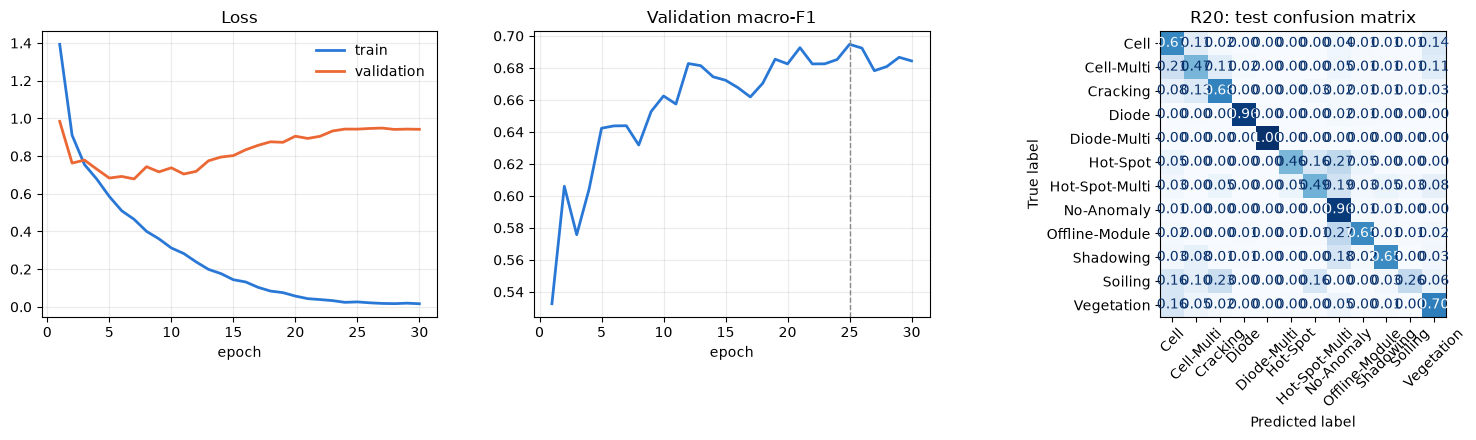

R20 logged in experiment_log.xlsx
[23:46:07] saved: runs\R20_20261028-233859
[23:46:07] ===== R21: ResNet50TL, 12 classes, balance = sqrt =====
[23:46:07] folder runs\R21_20261028-234607 | 23,532,620 parameters | lr 0.0003 | epochs 30 | batch 128 | NVIDIA GeForce RTX 4070 Ti
[23:46:21] epoch  1 | lr 3.00e-04 | train loss 1.411 acc 0.532 | val loss 0.898 acc 0.710 macro-F1 0.523 * | 14s
[23:46:35] epoch  2 | lr 2.99e-04 | train loss 0.944 acc 0.673 | val loss 0.802 acc 0.725 macro-F1 0.559 * | 28s
[23:46:49] epoch  3 | lr 2.97e-04 | train loss 0.778 acc 0.730 | val loss 0.721 acc 0.763 macro-F1 0.624 * | 42s
[23:47:03] epoch  4 | lr 2.93e-04 | train loss 0.680 acc 0.763 | val loss 0.716 acc 0.770 macro-F1 0.644 * | 56s
[23:47:17] epoch  5 | lr 2.87e-04 | train loss 0.601 acc 0.787 | val loss 0.701 acc 0.774 macro-F1 0.643 | 70s
[23:47:30] epoch  6 | lr 2.80e-04 | train loss 0.523 acc 0.822 | val loss 0.716 acc 0.771 macro-F1 0.636 | 83s
[23:47:44] epoch  7 | lr 2.71e-04 | train loss 0.4

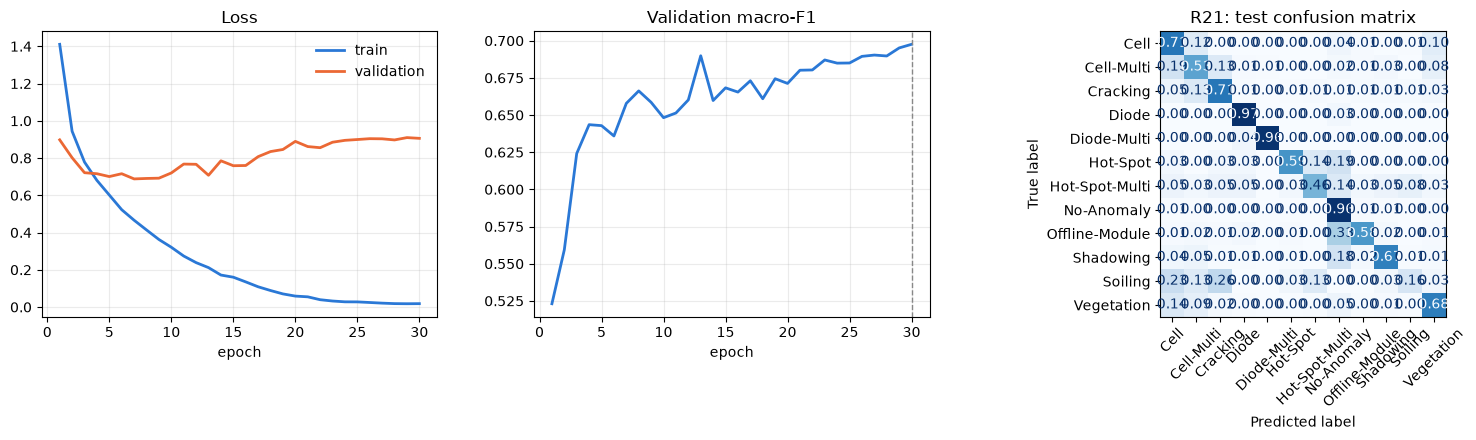

R21 logged in experiment_log.xlsx
[23:53:01] saved: runs\R21_20261028-234607
[23:53:01] ===== R22: ResNet50TL, 12 classes, balance = sqrt =====
[23:53:01] folder runs\R22_20261028-235301 | 23,532,620 parameters | lr 0.0003 | epochs 30 | batch 128 | NVIDIA GeForce RTX 4070 Ti
[23:53:15] epoch  1 | lr 3.00e-04 | train loss 1.406 acc 0.536 | val loss 0.920 acc 0.692 macro-F1 0.544 * | 14s
[23:53:29] epoch  2 | lr 2.99e-04 | train loss 0.929 acc 0.681 | val loss 0.832 acc 0.725 macro-F1 0.578 * | 27s
[23:53:42] epoch  3 | lr 2.97e-04 | train loss 0.753 acc 0.740 | val loss 0.717 acc 0.766 macro-F1 0.613 * | 41s
[23:53:56] epoch  4 | lr 2.93e-04 | train loss 0.661 acc 0.766 | val loss 0.717 acc 0.763 macro-F1 0.626 * | 55s
[23:54:09] epoch  5 | lr 2.87e-04 | train loss 0.595 acc 0.792 | val loss 0.718 acc 0.767 macro-F1 0.638 * | 68s
[23:54:23] epoch  6 | lr 2.80e-04 | train loss 0.522 acc 0.817 | val loss 0.750 acc 0.757 macro-F1 0.617 | 82s
[23:54:37] epoch  7 | lr 2.71e-04 | train loss 0

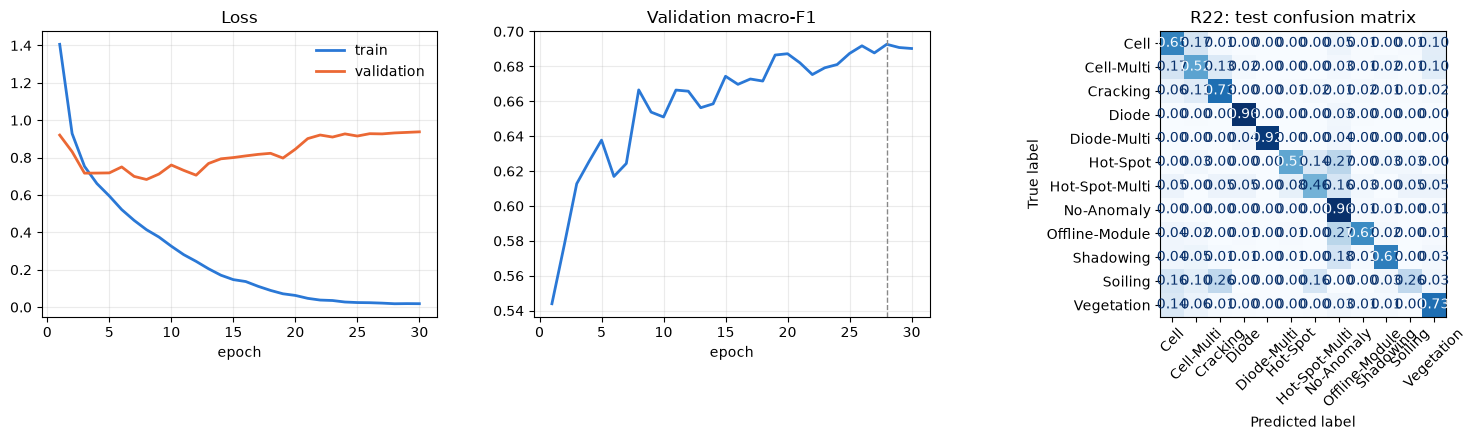

R22 logged in experiment_log.xlsx
[23:59:51] saved: runs\R22_20261028-235301
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\uSeR/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100.0%


[23:59:52] ===== R23: EffNetB0TL, 12 classes, balance = sqrt =====
[23:59:52] folder runs\R23_20261028-235952 | 4,022,920 parameters | lr 0.0003 | epochs 30 | batch 128 | NVIDIA GeForce RTX 4070 Ti
[00:00:32] epoch  1 | lr 3.00e-04 | train loss 1.486 acc 0.508 | val loss 0.840 acc 0.728 macro-F1 0.550 * | 40s
[00:00:41] epoch  2 | lr 2.99e-04 | train loss 0.952 acc 0.672 | val loss 0.763 acc 0.754 macro-F1 0.619 * | 49s
[00:00:49] epoch  3 | lr 2.97e-04 | train loss 0.775 acc 0.733 | val loss 0.719 acc 0.758 macro-F1 0.621 * | 57s
[00:00:57] epoch  4 | lr 2.93e-04 | train loss 0.675 acc 0.767 | val loss 0.651 acc 0.784 macro-F1 0.651 * | 65s
[00:01:06] epoch  5 | lr 2.87e-04 | train loss 0.586 acc 0.799 | val loss 0.648 acc 0.795 macro-F1 0.664 * | 74s
[00:01:14] epoch  6 | lr 2.80e-04 | train loss 0.498 acc 0.824 | val loss 0.690 acc 0.774 macro-F1 0.652 | 82s
[00:01:23] epoch  7 | lr 2.71e-04 | train loss 0.443 acc 0.847 | val loss 0.665 acc 0.795 macro-F1 0.671 * | 91s
[00:01:31] ep

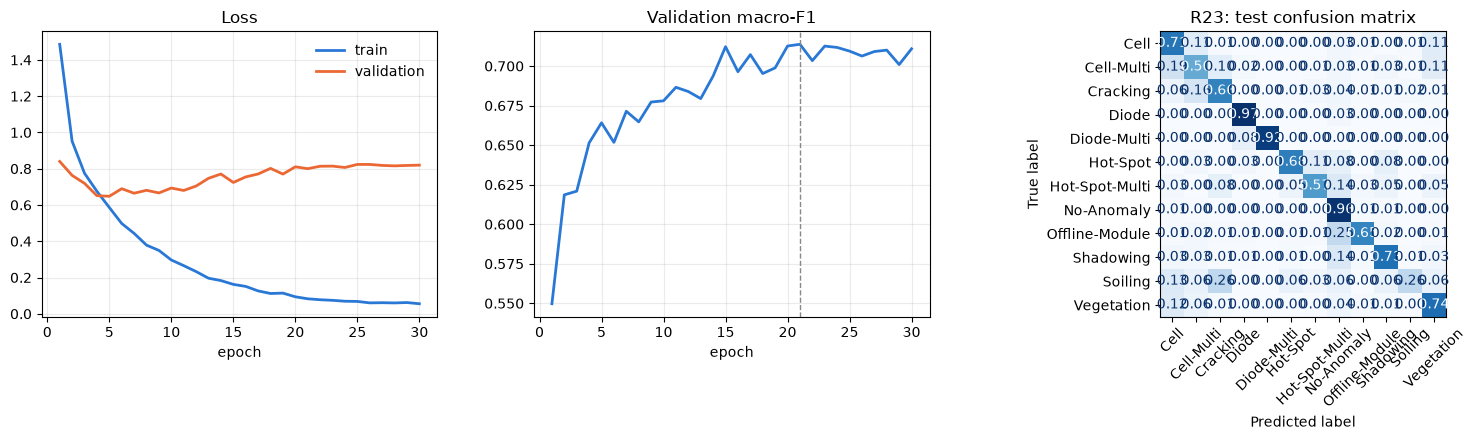

R23 logged in experiment_log.xlsx
[00:04:36] saved: runs\R23_20261028-235952
[00:04:37] ===== R24: EffNetB0TL, 12 classes, balance = sqrt =====
[00:04:37] folder runs\R24_20261029-000436 | 4,022,920 parameters | lr 0.0003 | epochs 30 | batch 128 | NVIDIA GeForce RTX 4070 Ti
[00:04:45] epoch  1 | lr 3.00e-04 | train loss 1.476 acc 0.515 | val loss 0.905 acc 0.703 macro-F1 0.547 * | 8s
[00:04:53] epoch  2 | lr 2.99e-04 | train loss 0.967 acc 0.671 | val loss 0.740 acc 0.754 macro-F1 0.620 * | 17s
[00:05:02] epoch  3 | lr 2.97e-04 | train loss 0.780 acc 0.727 | val loss 0.692 acc 0.769 macro-F1 0.626 * | 25s
[00:05:10] epoch  4 | lr 2.93e-04 | train loss 0.670 acc 0.769 | val loss 0.693 acc 0.765 macro-F1 0.641 * | 33s
[00:05:18] epoch  5 | lr 2.87e-04 | train loss 0.573 acc 0.797 | val loss 0.633 acc 0.795 macro-F1 0.661 * | 42s
[00:05:27] epoch  6 | lr 2.80e-04 | train loss 0.500 acc 0.824 | val loss 0.642 acc 0.790 macro-F1 0.658 | 50s
[00:05:35] epoch  7 | lr 2.71e-04 | train loss 0.4

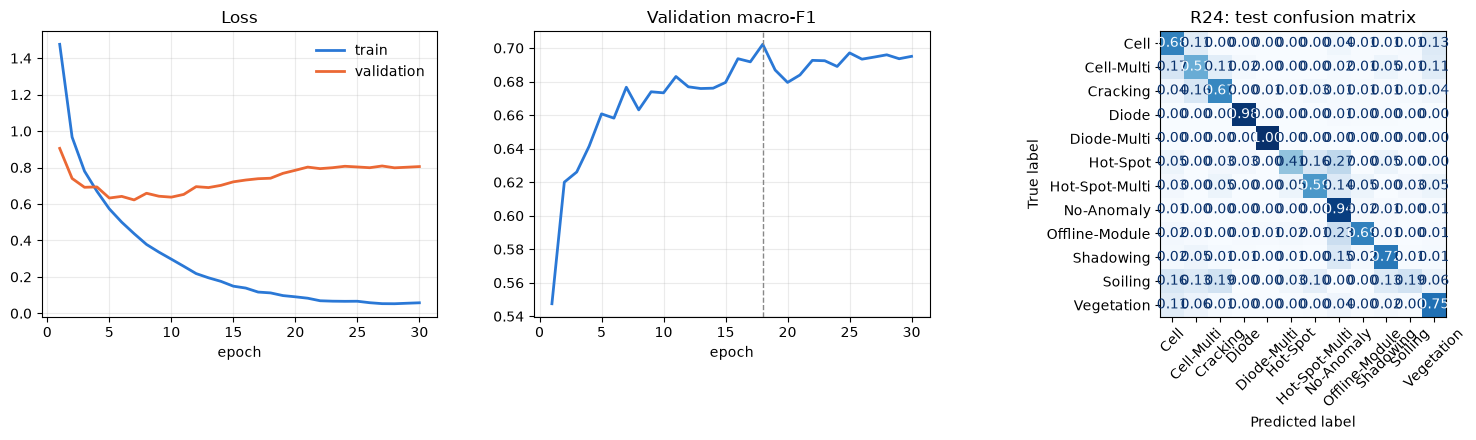

R24 logged in experiment_log.xlsx
[00:08:49] saved: runs\R24_20261029-000436
[00:08:49] ===== R25: EffNetB0TL, 12 classes, balance = sqrt =====
[00:08:49] folder runs\R25_20261029-000849 | 4,022,920 parameters | lr 0.0003 | epochs 30 | batch 128 | NVIDIA GeForce RTX 4070 Ti
[00:08:58] epoch  1 | lr 3.00e-04 | train loss 1.479 acc 0.517 | val loss 0.897 acc 0.699 macro-F1 0.534 * | 8s
[00:09:06] epoch  2 | lr 2.99e-04 | train loss 0.952 acc 0.671 | val loss 0.739 acc 0.759 macro-F1 0.614 * | 17s
[00:09:14] epoch  3 | lr 2.97e-04 | train loss 0.781 acc 0.729 | val loss 0.713 acc 0.761 macro-F1 0.630 * | 25s
[00:09:23] epoch  4 | lr 2.93e-04 | train loss 0.663 acc 0.764 | val loss 0.654 acc 0.784 macro-F1 0.641 * | 34s
[00:09:31] epoch  5 | lr 2.87e-04 | train loss 0.582 acc 0.805 | val loss 0.638 acc 0.799 macro-F1 0.668 * | 42s
[00:09:39] epoch  6 | lr 2.80e-04 | train loss 0.500 acc 0.823 | val loss 0.635 acc 0.808 macro-F1 0.675 * | 50s
[00:09:48] epoch  7 | lr 2.71e-04 | train loss 0

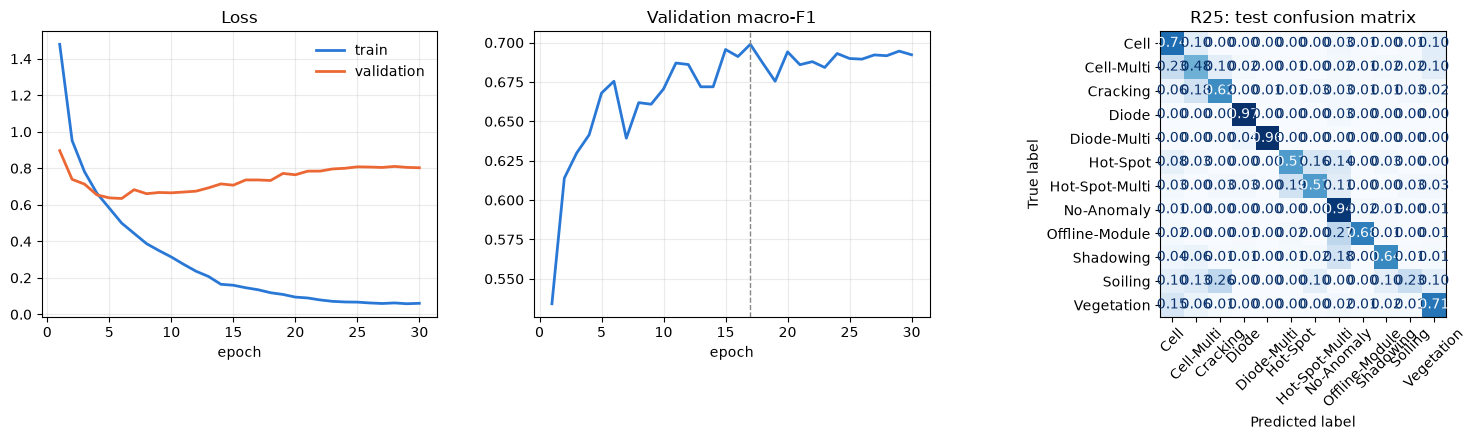

R25 logged in experiment_log.xlsx
[00:13:01] saved: runs\R25_20261029-000849
                     runs  n    params  acc_mean  acc_std  f1_mean  f1_std  f1_5_mean  f1_5_std  fault_mean   time_s
model                                                                                                               
ResNet18TL  R10, R16, R17  3  11182668     0.834    0.004    0.704   0.006      0.844     0.006       0.947  139.195
EffNetB0TL  R23, R24, R25  3   4022920     0.825    0.007    0.689   0.017      0.831     0.006       0.941  261.031
ResNet50TL  R20, R21, R22  3  23532620     0.823    0.004    0.685   0.004      0.821     0.003       0.942  414.127


In [9]:
plan_big = [("R20", "ResNet50TL", 42), ("R21", "ResNet50TL", 1), ("R22", "ResNet50TL", 2),
            ("R23", "EffNetB0TL", 42), ("R24", "EffNetB0TL", 1), ("R25", "EffNetB0TL", 2)]
cols = ["run_id", "rerun_of", "model", "classes", "balance", "seed", "val_f1", "test_acc", "test_f1", "test_f1_as_5", "fault_acc", "train_time", "params"]
for rid, mname, sd in plan_big:
    r = run_experiment(rid, mname, "12", balance="sqrt", epochs=30, lr=3e-4, seed=sd,
                       note=f"Bigger/other backbone check: {mname}, same recipe as R10 (seed {sd})")
    results.append(r)
    new = pd.DataFrame([r]).reindex(columns=cols)
    old = pd.read_csv("results_05.csv").reindex(columns=cols) if Path("results_05.csv").exists() else pd.DataFrame(columns=cols)
    pd.concat([old[~old.run_id.isin(new.run_id)], new], ignore_index=True).to_csv("results_05.csv", index=False)

# compare the three backbones (originals only, 12 classes, sampler 1/sqrt(n))
t = pd.read_csv("results_05.csv")
if "rerun_of" not in t: t["rerun_of"] = np.nan
t = t[t.rerun_of.isna() & (t["classes"].astype(str) == "12") & (t.balance == "sqrt")]
cmp_models = (t.groupby("model")
                .agg(runs=("run_id", lambda x: ", ".join(x)), n=("run_id", "size"), params=("params", "first"),
                     acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
                     f1_mean=("test_f1", "mean"), f1_std=("test_f1", "std"),
                     f1_5_mean=("test_f1_as_5", "mean"), f1_5_std=("test_f1_as_5", "std"),
                     fault_mean=("fault_acc", "mean"), time_s=("train_time", "mean"))
                .round(3).sort_values("f1_5_mean", ascending=False))
cmp_models.to_csv("results_05_models.csv")
print(cmp_models.to_string())

## 16. How to read the results (questions for the report)
1. **R05 vs R04**: did balancing raise the recall of rare classes (Soiling, Cell-Multi, Diode-Multi)? Did No-Anomaly recall drop? (Balancing usually trades a little accuracy for a higher macro-F1.)
2. **R06 vs R05**: does the pretrained ResNet-18 beat the small CNN? Is the gain worth 14 × more parameters?
3. **R07 / R08 vs `test_f1_as_5` of R05 / R06**: is it better to train directly on 5 groups, or to train on 12 classes and merge afterwards?
4. Compare with the papers in the table at the top. Note that some papers oversample **before** splitting the data, which puts copies of the same image in both training and test sets and inflates their numbers. Here the test set is never resampled.